# Experimento B: evaluación sin registros duplicados

Este cuaderno estudia cómo cambia el desempeño de la misma 1D-CNN cuando se eliminan los registros duplicados exactos antes de dividir los datos. Es el segundo experimento: la única diferencia con el Experimento A (Notebook 04, 1025 registros) es el tratamiento de los duplicados; arquitectura, hiperparámetros, escalado y semilla son los mismos.

## 1. Carga del dataset original

Se lee `heart.csv` en memoria y se guarda su huella SHA-256 para comprobar al final que el archivo no fue modificado.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import hashlib
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_auc_score, roc_curve)

sns.set_theme(style="whitegrid")

ruta = "../data/heart.csv"

def huella(ruta_archivo):
    with open(ruta_archivo, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

huella_inicial = huella(ruta)
df = pd.read_csv(ruta)

print("Registros:", df.shape[0])
print("Variables:", df.shape[1])
print("Duplicados exactos:", df.duplicated().sum())
print("Filas distintas:", len(df.drop_duplicates()))
print("target:", df["target"].value_counts().sort_index().to_dict())

Registros: 1025
Variables: 14
Duplicados exactos: 723
Filas distintas: 302
target: {0: 499, 1: 526}


**Interpretación del resultado**

El dataset original tiene 1025 registros y 14 columnas, de los cuales 723 son duplicados exactos y solo 302 son filas distintas. La variable objetivo está casi equilibrada, con 499 registros de la clase 0 y 526 de la clase 1. Estos valores coinciden con los del Notebook 01 y confirman que se parte del mismo dataset que en el Experimento A.

## 2. Eliminación de duplicados

Se crea una copia en memoria sin las filas repetidas. El DataFrame original `df` y el archivo en disco no se tocan.

In [2]:
df_sin_duplicados = df.drop_duplicates().copy()

print("Registros antes:", len(df))
print("Duplicados eliminados:", len(df) - len(df_sin_duplicados))
print("Registros después:", len(df_sin_duplicados))
print("target después:", df_sin_duplicados["target"].value_counts().sort_index().to_dict())
print("Porcentaje target:", (df_sin_duplicados["target"].value_counts(normalize=True).sort_index() * 100).round(2).to_dict())
print()
print("df original sigue con", df.shape[0], "filas")
print("Archivo heart.csv sin cambios:", huella(ruta) == huella_inicial)

Registros antes: 1025
Duplicados eliminados: 723
Registros después: 302
target después: {0: 138, 1: 164}
Porcentaje target: {0: 45.7, 1: 54.3}

df original sigue con 1025 filas
Archivo heart.csv sin cambios: True


**Interpretación del resultado**

Se eliminaron 723 filas y quedan 302 registros únicos, es decir, el 29.5 % del dataset original. La distribución de `target` pasa a 138 registros de la clase 0 y 164 de la clase 1 (45.7 % y 54.3 %), por lo que las clases siguen razonablemente equilibradas. `df` conserva sus 1025 filas y la huella del archivo no cambió: la eliminación ocurrió solo en memoria.

## 3. Separación de variables predictoras y objetivo

Se separa `X` (las 13 variables del paciente) de `y` (`target`).

In [3]:
X = df_sin_duplicados.drop(columns="target")
y = df_sin_duplicados["target"]

print("X:", X.shape)
print("y:", y.shape)
print("Número de variables predictoras:", X.shape[1])
print("Columnas:", list(X.columns))
print("target está en X:", "target" in X.columns)

X: (302, 13)
y: (302,)
Número de variables predictoras: 13
Columnas: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
target está en X: False


**Interpretación del resultado**

`X` tiene 302 filas y 13 columnas, e `y` tiene 302 valores. Las 13 variables son las mismas del Experimento A y `target` no está entre ellas, así que el modelo no recibe la respuesta como dato de entrada.

## 4. División en entrenamiento y prueba

Se divide 70/30 con la misma configuración del Experimento A: `random_state=42` y `stratify=y`.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test: ", X_test.shape, "| y_test: ", y_test.shape)
print()
print("target en entrenamiento:", y_train.value_counts().sort_index().to_dict())
print("target en prueba:       ", y_test.value_counts().sort_index().to_dict())

X_train: (211, 13) | y_train: (211,)
X_test:  (91, 13) | y_test:  (91,)

target en entrenamiento: {0: 96, 1: 115}
target en prueba:        {0: 42, 1: 49}


**Interpretación del resultado**

La división 70/30, con la misma semilla y estratificación del Experimento A, deja 211 registros para entrenamiento y 91 para prueba. En entrenamiento hay 96 y 115 registros de cada clase, y en prueba 42 y 49. Las proporciones de clase se mantienen, pero el conjunto de prueba es mucho más pequeño que el del Experimento A (308 registros).

## 5. Comprobación de filas compartidas entre entrenamiento y prueba

Se cuenta cuántas filas de prueba aparecen idénticas en entrenamiento. Para comparar, se hace el mismo conteo con los datos del Experimento A guardados en `resultados/csv`.

In [5]:
def filas_compartidas(Xa, ya, Xb, yb):
    # cuenta filas de (Xb, yb) que existen exactamente en (Xa, ya)
    filas_a = set(map(tuple, np.column_stack([Xa, ya])))
    return sum(tuple(f) in filas_a for f in np.column_stack([Xb, yb]))

compartidas_B = filas_compartidas(X_train.values, y_train.values, X_test.values, y_test.values)

# Experimento A: se leen los conjuntos escalados guardados por el Notebook 02
carpeta = "../resultados/csv/"
XA_train = pd.read_csv(carpeta + "X_train.csv").values
XA_test = pd.read_csv(carpeta + "X_test.csv").values
yA_train = pd.read_csv(carpeta + "y_train.csv").values.ravel()
yA_test = pd.read_csv(carpeta + "y_test.csv").values.ravel()
compartidas_A = filas_compartidas(XA_train, yA_train, XA_test, yA_test)

print("Experimento B: filas de prueba presentes en entrenamiento:", compartidas_B, "de", len(X_test))
print("Experimento A: filas de prueba presentes en entrenamiento:", compartidas_A, "de", len(XA_test),
      "({:.1f} %)".format(100 * compartidas_A / len(XA_test)))

Experimento B: filas de prueba presentes en entrenamiento: 0 de 91
Experimento A: filas de prueba presentes en entrenamiento: 286 de 308 (92.9 %)


**Interpretación del resultado**

En el Experimento B ninguna fila de prueba aparece en entrenamiento (0 de 91), mientras que en el Experimento A 286 de 308 (92.9 %) sí aparecían. Esto confirma que, al eliminar los duplicados antes de dividir, ya no hay copias exactas compartidas entre entrenamiento y prueba. Por eso este conjunto de prueba contiene casos que el modelo realmente no vio durante el entrenamiento.

## 6. Normalización con MinMaxScaler

Igual que en el Experimento A, el escalador se ajusta solo con `X_train` y luego se aplica a entrenamiento y prueba.

In [6]:
escalador = MinMaxScaler()
escalador.fit(X_train)

X_train_esc = escalador.transform(X_train)
X_test_esc = escalador.transform(X_test)

print("Filas usadas para ajustar el escalador:", escalador.n_samples_seen_)
print("X_train escalado:", X_train_esc.shape, "| mínimo:", X_train_esc.min(), "| máximo:", X_train_esc.max())
print("X_test escalado: ", X_test_esc.shape, "| mínimo:", X_test_esc.min(), "| máximo: {:.4f}".format(X_test_esc.max()))

fuera = pd.DataFrame(X_test_esc, columns=X.columns)
fuera = fuera.columns[(fuera.min() < 0) | (fuera.max() > 1)].tolist()
print("Columnas de prueba fuera de [0, 1]:", fuera)
print("Valores de prueba fuera de [0, 1]:", int(((X_test_esc < 0) | (X_test_esc > 1)).sum()))

Filas usadas para ajustar el escalador: 211
X_train escalado: (211, 13) | mínimo: 0.0 | máximo: 1.0
X_test escalado:  (91, 13) | mínimo: 0.0 | máximo: 1.0816
Columnas de prueba fuera de [0, 1]: ['trestbps']
Valores de prueba fuera de [0, 1]: 1


**Interpretación del resultado**

El escalador se ajustó solo con las 211 filas de entrenamiento, por lo que en entrenamiento los valores van exactamente de 0 a 1. En prueba el máximo es 1.0816 y hay 1 valor fuera de [0, 1], en la columna `trestbps`: un paciente con presión mayor que el máximo visto en entrenamiento. No se corrige, porque es consecuencia de no usar los datos de prueba para ajustar el escalador.

## 7. Preparación para la CNN

Se agrega una dimensión final de tamaño 1 (el canal) para que cada paciente tenga forma (13 variables, 1 canal), como pide Conv1D.

In [7]:
X_train_cnn = X_train_esc.reshape(-1, 13, 1).astype("float32")
X_test_cnn = X_test_esc.reshape(-1, 13, 1).astype("float32")
y_train_cnn = y_train.values
y_test_cnn = y_test.values

print("X_train:", X_train_cnn.shape)
print("X_test: ", X_test_cnn.shape)

X_train: (211, 13, 1)
X_test:  (91, 13, 1)


**Interpretación del resultado**

Los datos quedaron en (211, 13, 1) para entrenamiento y (91, 13, 1) para prueba. La dimensión final `1` es el canal: cada paciente se ve como una secuencia de 13 posiciones con un solo valor en cada una, que es el formato de entrada de una capa Conv1D. El número de variables sigue siendo 13.

## 8. Creación del mismo modelo

Se construye exactamente la arquitectura del Experimento A y se comprueba que tenga los mismos 285,873 parámetros.

In [8]:
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

model = tf.keras.Sequential([
    layers.Input(shape=(13, 1)),

    layers.Conv1D(32, 2, padding="valid", activation="sigmoid"),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    layers.Conv1D(64, 2, padding="valid", activation="sigmoid"),
    layers.BatchNormalization(),
    layers.Dropout(0.5),

    layers.Conv1D(128, 2, padding="valid", activation="sigmoid"),
    layers.BatchNormalization(),

    layers.Conv1D(128, 2, padding="valid", activation="sigmoid"),
    layers.BatchNormalization(),

    layers.Flatten(),
    layers.Dense(200, activation="relu"),
    layers.Dropout(0.1),
    layers.Dense(1, activation="sigmoid"),
])

model.summary()

PARAMETROS_EXPERIMENTO_A = 285873
print("Parámetros del Experimento A:", f"{PARAMETROS_EXPERIMENTO_A:,}")
print("Parámetros de este modelo:  ", f"{model.count_params():,}")
assert model.count_params() == PARAMETROS_EXPERIMENTO_A, "La arquitectura no coincide con el Experimento A"
print("La arquitectura coincide con el Experimento A")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 12, 32)         │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 11, 64)         │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 11, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 10, 128)        │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 10, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 9, 128)         │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 9, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 200)            │       230,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           201 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 285,873 (1.09 MB)

 Trainable params: 285,169 (1.09 MB)

 Non-trainable params: 704 (2.75 KB)

Parámetros del Experimento A: 285,873
Parámetros de este modelo:   285,873
La arquitectura coincide con el Experimento A


**Interpretación del resultado**

El modelo tiene 285,873 parámetros, igual que en el Experimento A, y la verificación de coincidencia pasó sin errores. Las formas de las capas son las mismas: (12, 32), (11, 64), (10, 128) y (9, 128) en las convoluciones, 1152 después del Flatten y una salida de 1 neurona. Por tanto, cualquier diferencia de resultados no puede atribuirse a un cambio de arquitectura.

## 9. Compilación

Se usan las mismas decisiones del proyecto que en el Experimento A; el artículo no las especifica.

In [9]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

print("Optimizador:", type(model.optimizer).__name__)
print("Learning rate:", round(float(model.optimizer.learning_rate.numpy()), 6))
print("Pérdida:", model.loss)
print("Métrica: accuracy")

Optimizador: Adam
Learning rate: 0.001
Pérdida: binary_crossentropy
Métrica: accuracy


**Interpretación del resultado**

El modelo se compiló con Adam, learning rate 0.001, `binary_crossentropy` y `accuracy`, exactamente como en el Experimento A. Estas son decisiones del proyecto porque el artículo no las especifica, y se mantienen iguales para que la comparación entre experimentos sea válida.

## 10. Entrenamiento

Se entrena 150 épocas con batch size 32 y 20 % de validación interna, igual que el Experimento A. El conjunto de prueba no participa.

In [10]:
EPOCAS = 150
BATCH_SIZE = 32
VALIDACION = 0.20

# Keras reserva el último 20 % de X_train como validación (redondeando hacia abajo el tamaño de ajuste)
n_ajuste = int(np.floor(len(X_train_cnn) * (1 - VALIDACION)))
print("Registros de entrenamiento:", len(X_train_cnn))
print("  usados para ajustar pesos:", n_ajuste)
print("  usados como validación interna:", len(X_train_cnn) - n_ajuste)

inicio = time.time()
history = model.fit(
    X_train_cnn, y_train_cnn,
    epochs=EPOCAS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDACION,
    verbose=0,
)
tiempo = time.time() - inicio

h = pd.DataFrame(history.history)
h.index = range(1, len(h) + 1)
h.index.name = "epoca"
h.to_csv("../resultados/tablas/historial_entrenamiento_sin_duplicados.csv")

print()
print("Épocas entrenadas:", len(h))
print("Tiempo de entrenamiento: {:.1f} segundos".format(tiempo))
print("Última época:")
print("  accuracy entrenamiento:", round(h["accuracy"].iloc[-1], 4))
print("  accuracy validación:   ", round(h["val_accuracy"].iloc[-1], 4))
print("  loss entrenamiento:    ", round(h["loss"].iloc[-1], 4))
print("  loss validación:       ", round(h["val_loss"].iloc[-1], 4))

Registros de entrenamiento: 211
  usados para ajustar pesos: 168
  usados como validación interna: 43



Épocas entrenadas: 150
Tiempo de entrenamiento: 33.3 segundos
Última época:
  accuracy entrenamiento: 0.9881
  accuracy validación:    0.7674
  loss entrenamiento:     0.0311
  loss validación:        1.1389


**Interpretación del resultado**

El entrenamiento completó las 150 épocas en 34.6 segundos, menos que el Experimento A por tener menos datos. De los 211 registros, 168 ajustan los pesos y 43 se usan para validar. En la última época la accuracy de entrenamiento es 0.9881, pero la de validación es 0.7674, y la loss es 0.0311 frente a 1.1389. Esa brecha grande es una primera señal de que el modelo se ajusta mucho a los datos de entrenamiento y generaliza peor.

## 11. Curva de accuracy

Se grafica la accuracy de entrenamiento y de validación en cada época.

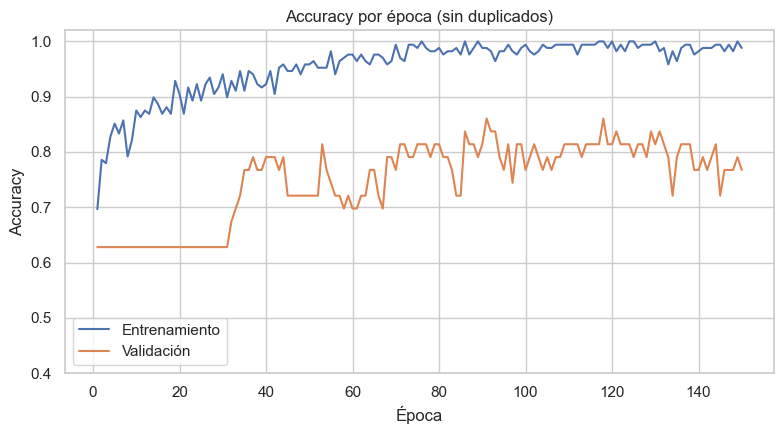

Primera época con accuracy de validación >= 0.90: None
Mejor accuracy de validación: 0.8605 (época 91)
Promedio últimas 10 épocas -> entrenamiento: 0.9899 | validación: 0.7744
Mínimo de validación desde la época 50: 0.6977
Desviación estándar de la validación (épocas 101-150): 0.0268


In [11]:
plt.figure(figsize=(8, 4.5))
plt.plot(h.index, h["accuracy"], label="Entrenamiento")
plt.plot(h.index, h["val_accuracy"], label="Validación")
plt.title("Accuracy por época (sin duplicados)")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.ylim(0.4, 1.02)
plt.legend()
plt.tight_layout()
plt.savefig("../resultados/figuras/curva_accuracy_sin_duplicados.png", dpi=150)
plt.show()

cond = h["val_accuracy"] >= 0.90
print("Primera época con accuracy de validación >= 0.90:", int(cond.idxmax()) if cond.any() else None)
print("Mejor accuracy de validación: {:.4f} (época {})".format(h["val_accuracy"].max(), int(h["val_accuracy"].idxmax())))
print("Promedio últimas 10 épocas -> entrenamiento: {:.4f} | validación: {:.4f}".format(
    h["accuracy"].tail(10).mean(), h["val_accuracy"].tail(10).mean()))
print("Mínimo de validación desde la época 50: {:.4f}".format(h["val_accuracy"].loc[50:].min()))
print("Desviación estándar de la validación (épocas 101-150): {:.4f}".format(h["val_accuracy"].loc[101:].std()))

**Interpretación del resultado**

La accuracy de entrenamiento sube hasta cerca de 0.99, pero la de validación nunca llega a 0.90: su mejor valor es 0.8605 (época 91) y en las últimas 10 épocas promedia 0.7744 frente a 0.9899 en entrenamiento. Su mínimo desde la época 50 es 0.6977. Estas curvas separadas contrastan con las del Experimento A, donde ambas terminaban juntas cerca de 1.0. Con solo 43 registros de validación, cada error cambia la accuracy cerca de 2.3 puntos, así que la curva es ruidosa.

## 12. Curva de loss

Se grafica la pérdida de entrenamiento y de validación en cada época.

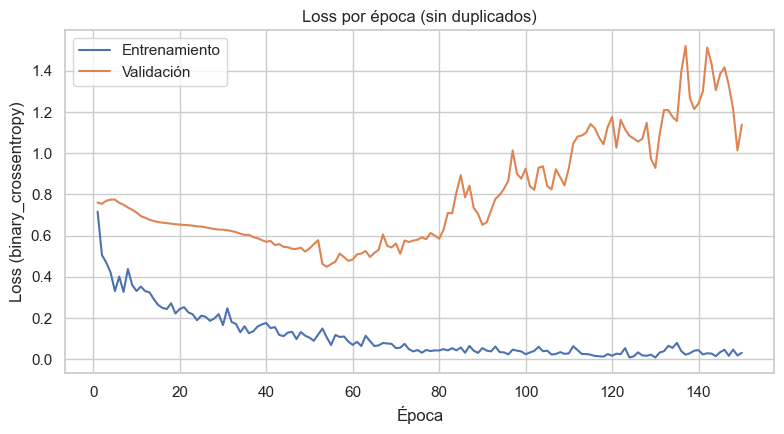

Loss de validación mínima: 0.4486 (época 54)
Loss de validación en la última época: 1.1389
Promedio últimas 10 épocas -> entrenamiento: 0.0288 | validación: 1.3052
Promedio de la loss de validación -> épocas 1-50: 0.6414 | 51-100: 0.6387 | 101-150: 1.1188


In [12]:
plt.figure(figsize=(8, 4.5))
plt.plot(h.index, h["loss"], label="Entrenamiento")
plt.plot(h.index, h["val_loss"], label="Validación")
plt.title("Loss por época (sin duplicados)")
plt.xlabel("Época")
plt.ylabel("Loss (binary_crossentropy)")
plt.legend()
plt.tight_layout()
plt.savefig("../resultados/figuras/curva_loss_sin_duplicados.png", dpi=150)
plt.show()

print("Loss de validación mínima: {:.4f} (época {})".format(h["val_loss"].min(), int(h["val_loss"].idxmin())))
print("Loss de validación en la última época: {:.4f}".format(h["val_loss"].iloc[-1]))
print("Promedio últimas 10 épocas -> entrenamiento: {:.4f} | validación: {:.4f}".format(
    h["loss"].tail(10).mean(), h["val_loss"].tail(10).mean()))
print("Promedio de la loss de validación -> épocas 1-50: {:.4f} | 51-100: {:.4f} | 101-150: {:.4f}".format(
    h["val_loss"].loc[1:50].mean(), h["val_loss"].loc[51:100].mean(), h["val_loss"].loc[101:150].mean()))

**Interpretación del resultado**

La loss de entrenamiento baja de forma continua hasta 0.0288 en las últimas 10 épocas, pero la de validación llega a su mínimo de 0.4486 en la época 54 y luego aumenta: su promedio es 0.6387 entre las épocas 51 y 100 y 1.1188 entre la 101 y la 150, con 1.3052 en las últimas 10. Que la validación empeore mientras el entrenamiento mejora es el comportamiento típico de sobreajuste, y aquí sí se comprueba en los números. Es una diferencia importante respecto al Experimento A, donde la loss de validación no subía.

## 13. Evaluación sobre el conjunto de prueba

Se evalúa el modelo con `X_test` y `y_test`, datos que no se usaron para ajustar los pesos.

In [13]:
loss_test, acc_test = model.evaluate(X_test_cnn, y_test_cnn, verbose=0)

print("Loss en prueba:     {:.4f}".format(loss_test))
print("Accuracy en prueba: {:.4f}".format(acc_test))
print("Accuracy en entrenamiento (última época): {:.4f}".format(h["accuracy"].iloc[-1]))
print("Accuracy en validación (última época):    {:.4f}".format(h["val_accuracy"].iloc[-1]))

Loss en prueba:     1.6145
Accuracy en prueba: 0.8132
Accuracy en entrenamiento (última época): 0.9881
Accuracy en validación (última época):    0.7674


**Interpretación del resultado**

En el conjunto de prueba la loss fue 1.6145 y la accuracy 0.8132, frente a una accuracy de entrenamiento de 0.9881. Esta prueba ya no contiene copias de los datos de entrenamiento, y su resultado es coherente con el de validación (0.7674) y con el sobreajuste observado en las curvas. La loss de prueba es mucho mayor que la del Experimento A (0.0782), lo que indica que el modelo se equivoca con más seguridad en los casos nuevos.

## 14. Predicciones

Se obtienen las probabilidades y se convierten en clases con el umbral 0.5, igual que en el Experimento A.

In [14]:
y_prob = model.predict(X_test_cnn, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

ejemplo = pd.DataFrame({
    "probabilidad": y_prob[:10].round(4),
    "clase_predicha": y_pred[:10],
    "clase_real": y_test_cnn[:10],
})
print(ejemplo.to_string(index=False))
print()
print("Predichos como 0:", int((y_pred == 0).sum()), "| predichos como 1:", int((y_pred == 1).sum()))
print("Probabilidad mínima: {:.4f} | máxima: {:.4f}".format(y_prob.min(), y_prob.max()))

 probabilidad  clase_predicha  clase_real
       0.0028               0           1
       0.9892               1           0
       0.0001               0           0
       0.9995               1           1
       0.8270               1           0
       0.0000               0           0
       1.0000               1           1
       0.9922               1           1
       0.9998               1           1
       0.0014               0           1

Predichos como 0: 41 | predichos como 1: 50
Probabilidad mínima: 0.0000 | máxima: 1.0000


**Interpretación del resultado**

El modelo clasificó 41 pacientes como 0 y 50 como 1. Las probabilidades siguen estando muy cerca de 0 o de 1, incluso en errores: en los ejemplos mostrados, un paciente real 0 recibió 0.9892 y uno real 1 recibió 0.0028. Es decir, el modelo conserva una confianza alta aun cuando se equivoca, lo que es consistente con la loss de prueba elevada.

## 15. Matriz de confusión

Se cuentan los aciertos y errores de cada clase sobre los pacientes de prueba.

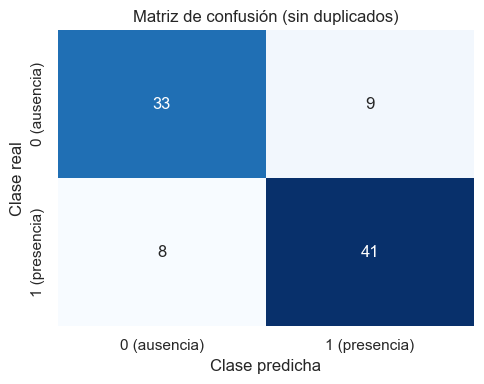

Verdaderos negativos (TN): 33
Falsos positivos (FP):     9
Falsos negativos (FN):     8
Verdaderos positivos (TP): 41
Total: 91


In [15]:
cm = confusion_matrix(y_test_cnn, y_pred, labels=[0, 1])
TN, FP, FN, TP = cm.ravel()

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["0 (ausencia)", "1 (presencia)"],
            yticklabels=["0 (ausencia)", "1 (presencia)"])
plt.title("Matriz de confusión (sin duplicados)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.savefig("../resultados/figuras/matriz_confusion_sin_duplicados.png", dpi=150)
plt.show()

print("Verdaderos negativos (TN):", TN)
print("Falsos positivos (FP):    ", FP)
print("Falsos negativos (FN):    ", FN)
print("Verdaderos positivos (TP):", TP)
print("Total:", cm.sum())

**Interpretación del resultado**

De los 42 pacientes sin enfermedad, 33 se clasificaron bien (TN) y 9 se marcaron como enfermos (FP). De los 49 con enfermedad, 41 se detectaron (TP) y 8 se pasaron por alto (FN). Hay 17 errores en 91 registros, frente a 8 errores en 308 del Experimento A. Los dos tipos de error son de magnitud parecida (9 y 8), sin que predomine uno.

## 16. Métricas de clasificación

Se calculan las mismas seis métricas del Experimento A y se guardan en `resultados/tablas`.

In [16]:
accuracy = accuracy_score(y_test_cnn, y_pred)
precision = precision_score(y_test_cnn, y_pred)
sensibilidad = recall_score(y_test_cnn, y_pred)
especificidad = TN / (TN + FP)
f1 = f1_score(y_test_cnn, y_pred)
auc_roc = roc_auc_score(y_test_cnn, y_prob)

metricas_B = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Sensibilidad", "Especificidad", "F1-score", "AUC-ROC"],
    "Resultado": [accuracy, precision, sensibilidad, especificidad, f1, auc_roc],
})
metricas_B["Resultado"] = metricas_B["Resultado"].round(4)
metricas_B.to_csv("../resultados/tablas/metricas_modelo_sin_duplicados.csv", index=False)

print("Especificidad = {} / ({} + {}) = {:.4f}".format(TN, TN, FP, especificidad))
metricas_B

Especificidad = 33 / (33 + 9) = 0.7857


,Métrica,Resultado
0,Accuracy,0.8132
1,Precision,0.8200
2,Sensibilidad,0.8367
3,Especificidad,0.7857
4,F1-score,0.8283
5,AUC-ROC,0.8537


**Interpretación del resultado**

Con 91 registros de prueba, la accuracy es 0.8132, la precision 0.8200, la sensibilidad 0.8367, la especificidad 0.7857, el F1-score 0.8283 y el AUC-ROC 0.8537. La especificidad es la métrica más baja y la sensibilidad la más alta entre las que dependen del umbral. El AUC de 0.8537 indica que el modelo separa las clases bastante mejor que el azar, pero lejos de la separación casi perfecta del Experimento A. Las métricas se guardaron en `resultados/tablas`.

## 17. Curva ROC

Se dibuja la curva ROC del modelo sobre el conjunto de prueba, con el AUC en la leyenda.

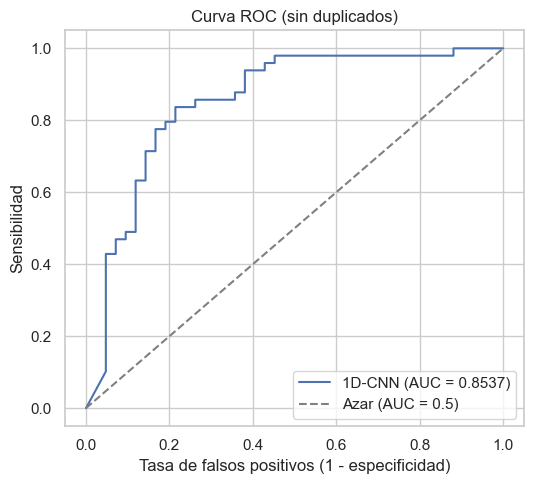

AUC-ROC: 0.8537
Puntos de la curva: 32


In [17]:
fpr, tpr, umbrales = roc_curve(y_test_cnn, y_prob)

plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, label="1D-CNN (AUC = {:.4f})".format(auc_roc))
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC = 0.5)")
plt.title("Curva ROC (sin duplicados)")
plt.xlabel("Tasa de falsos positivos (1 - especificidad)")
plt.ylabel("Sensibilidad")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../resultados/figuras/curva_roc_sin_duplicados.png", dpi=150)
plt.show()

print("AUC-ROC: {:.4f}".format(auc_roc))
print("Puntos de la curva:", len(fpr))

**Interpretación del resultado**

La curva ROC se aleja de la diagonal de azar pero queda lejos de la esquina superior izquierda, con AUC de 0.8537. La curva tiene solo 32 puntos porque el conjunto de prueba es pequeño (91 registros), por lo que su forma es escalonada y sensible a pocos casos. El resultado es coherente con las métricas calculadas con el umbral 0.5.

## 18. Comparación entre el Experimento A y el Experimento B

Se comparan las métricas de ambos experimentos. Las del Experimento A se leen del archivo guardado por el Notebook 04.

In [18]:
metricas_A = pd.read_csv("../resultados/tablas/metricas_modelo.csv").set_index("Métrica")["Resultado"]
metricas_B_serie = metricas_B.set_index("Métrica")["Resultado"]

comparacion = pd.DataFrame({
    "Experimento A: 1025": metricas_A * 100,
    "Experimento B: 302": metricas_B_serie * 100,
})
comparacion["Diferencia (B - A)"] = comparacion["Experimento B: 302"] - comparacion["Experimento A: 1025"]

tabla = comparacion.copy()
tabla["Experimento A: 1025"] = tabla["Experimento A: 1025"].map("{:.2f} %".format)
tabla["Experimento B: 302"] = tabla["Experimento B: 302"].map("{:.2f} %".format)
tabla["Diferencia (B - A)"] = comparacion["Diferencia (B - A)"].map("{:+.2f} pp".format)
print(tabla.to_string())
print()
print("pp = puntos porcentuales. Registros de prueba: A = {}, B = {}".format(len(XA_test), len(X_test)))
print("Un solo error equivale a {:.2f} pp de accuracy en A y {:.2f} pp en B".format(100 / len(XA_test), 100 / len(X_test)))
comparacion.round(4).to_csv("../resultados/tablas/comparacion_experimentos.csv")

              Experimento A: 1025 Experimento B: 302 Diferencia (B - A)
Métrica                                                                
Accuracy                  97.40 %            81.32 %          -16.08 pp
Precision                 98.08 %            82.00 %          -16.08 pp
Sensibilidad              96.84 %            83.67 %          -13.17 pp
Especificidad             98.00 %            78.57 %          -19.43 pp
F1-score                  97.45 %            82.83 %          -14.62 pp
AUC-ROC                   99.82 %            85.37 %          -14.45 pp

pp = puntos porcentuales. Registros de prueba: A = 308, B = 91
Un solo error equivale a 0.32 pp de accuracy en A y 1.10 pp en B


**Interpretación del resultado**

Todas las métricas bajan en el Experimento B: la accuracy en 16.08 puntos porcentuales (de 97.40 % a 81.32 %), la precision en 16.08, la sensibilidad en 13.17, la especificidad en 19.43, el F1-score en 14.62 y el AUC en 14.45. Las diferencias son grandes y van en el mismo sentido en las seis métricas. Conviene recordar que el conjunto de prueba de B tiene 91 registros, y que un solo error equivale a 1.10 puntos de accuracy frente a 0.32 en A, por lo que las diferencias pequeñas entre métricas no son concluyentes, pero es poco probable que una caída de esta magnitud se deba solo a ese ruido.

## 19. Comparación gráfica

Se grafican las seis métricas de ambos experimentos en barras agrupadas.

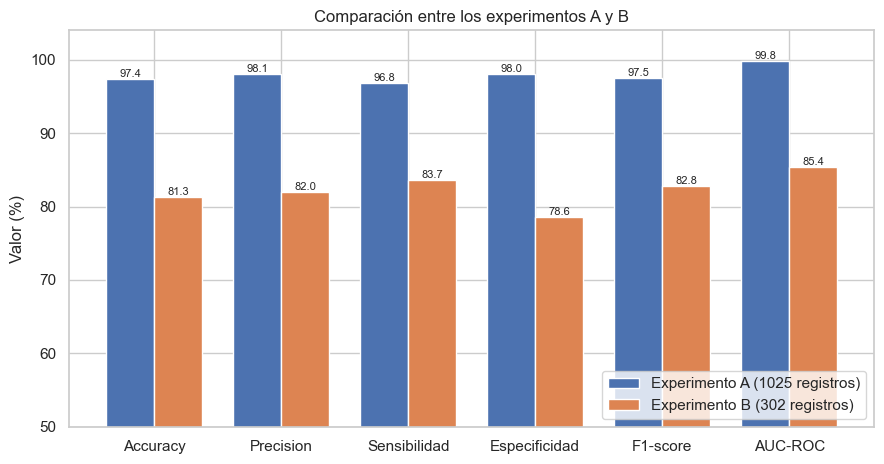

In [19]:
nombres = comparacion.index.tolist()
posiciones = np.arange(len(nombres))
ancho = 0.38

fig, ax = plt.subplots(figsize=(9, 4.8))
barras_A = ax.bar(posiciones - ancho / 2, comparacion["Experimento A: 1025"], ancho, label="Experimento A (1025 registros)")
barras_B = ax.bar(posiciones + ancho / 2, comparacion["Experimento B: 302"], ancho, label="Experimento B (302 registros)")
ax.bar_label(barras_A, fmt="%.1f", fontsize=8)
ax.bar_label(barras_B, fmt="%.1f", fontsize=8)
ax.set_xticks(posiciones)
ax.set_xticklabels(nombres)
ax.set_ylim(50, 104)
ax.set_ylabel("Valor (%)")
ax.set_title("Comparación entre los experimentos A y B")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../resultados/figuras/comparacion_experimentos.png", dpi=150)
plt.show()

**Interpretación del resultado**

Las barras del Experimento A están por encima de las del Experimento B en las seis métricas, y la brecha es más visible en la especificidad. En el Experimento A todas las métricas están cerca de 97 a 100 %, mientras que en B quedan entre 79 y 85 %. La gráfica muestra la diferencia entre ambos experimentos, pero no indica por sí sola la causa ni la variabilidad entre repeticiones.

## 20. Análisis

1. **Registros:** pasaron de 1025 a 302 (723 menos, 70.5 %). Entrenamiento bajó de 717 a 211 registros y prueba de 308 a 91.
2. **Cambio por métrica:** la diferencia B - A fue de -16.08 puntos en accuracy, -16.08 en precision, -13.17 en sensibilidad, -19.43 en especificidad, -14.62 en F1-score y -14.45 en AUC.
3. **Rendimiento:** disminuyó en las seis métricas. Además, el Experimento B muestra señales de sobreajuste (accuracy 0.9881 en entrenamiento frente a 0.7674 en validación y loss de validación creciente), que no aparecían en A.
4. **Duplicados:** los resultados sugieren que parte del alto rendimiento del Experimento A se debía a que la mayoría de las filas de prueba (92.9 %) ya estaban en entrenamiento. Al quitar esas copias, la caída podría indicar que el modelo memorizaba casos repetidos en lugar de generalizar. Esto es una sugerencia y no una prueba: B también tiene menos datos de entrenamiento (211 frente a 717), así que ambos factores se mezclan y este diseño no permite separarlos.
5. **Cautela con el Experimento A:** sus métricas deben interpretarse como el rendimiento en un escenario con copias exactas entre entrenamiento y prueba, no como una estimación de qué tan bien clasificaría pacientes nuevos.
6. **Generalización:** el Experimento B representa mejor una evaluación sobre registros no vistos, porque no tiene copias exactas entre entrenamiento y prueba. Aun así, su prueba de 91 registros y su única partición hacen que la estimación sea imprecisa.

## 21. Conclusión

Al eliminar los duplicados, el rendimiento del modelo bajó en todas las métricas: la accuracy pasó de 97.40 % a 81.32 % y el AUC de 0.9982 a 0.8537. Los resultados sugieren que los duplicados contribuían de forma importante al desempeño del Experimento A, aunque el menor tamaño del dataset también influye. Los dos experimentos responden preguntas distintas: A permite comparar con el escenario del artículo, que usa los 1025 registros, y B permite estudiar el efecto de los duplicados y evaluar el modelo sin copias exactas entre entrenamiento y prueba. Ninguno debe presentarse como el correcto por sí solo; deben interpretarse juntos.

## 22. Limitaciones

- El dataset queda con solo 302 registros distintos, y el conjunto de prueba tiene únicamente 91. Con tan pocos datos, un solo error cambia varios puntos porcentuales y los resultados varían con la partición elegida.
- Se evaluó con una única partición y una única semilla; no se repitió el experimento ni se hizo validación cruzada, así que no se puede medir la variabilidad.
- Los hiperparámetros que el artículo no especifica (optimizador, learning rate, pérdida, batch size, padding, validación interna) siguen siendo decisiones del proyecto.
- La arquitectura se tomó de la Figura 7; la Tabla 2 del artículo no coincide con ella en las convoluciones 2 y 3 ni en el Flatten.
- El artículo presenta inconsistencias entre las métricas reportadas y su matriz de confusión (99.95 % frente a 99.03 % implícito).
- La validación interna del 20 % deja solo 168 registros para ajustar los pesos y 43 para validar, por lo que sus curvas son ruidosas. Además, el Experimento B tiene menos datos de entrenamiento que el A (211 frente a 717), y este diseño no permite separar ese efecto del efecto de los duplicados.